# Fair-value model: map view

This notebook places the flats on a map of Madrid, using the barrio boundaries from the Ayuntamiento de Madrid geoportal and the geocoded addresses in `src/data/geo/geocoded_addresses.csv`.

It has three parts:
1. **Where the flats are, and how their labels cluster** (points and barrio choropleths).
2. **Density** (where listings are concentrated).
3. **A rent surface**: a model that uses coordinates to draw predicted rent across the city, with contour lines at fixed rent levels as "decision boundaries".

**Caveat:** geocoding is approximate. Some addresses only resolve to the street or the neighbourhood centre, and those are flagged in section 1.

In [1]:
import sys
from pathlib import Path

def find_repo_root(start: Path) -> Path:
    # Walk up from the notebook's working directory until the folder holding src/data/ is found.
    for candidate in [start, *start.parents]:
        if (candidate / "src" / "data" / "data_acquire.py").exists():
            return candidate
    raise RuntimeError(f"Could not find the MLProjectBAM repo above {start}. Open the notebook from inside the repo.")

REPO = find_repo_root(Path.cwd().resolve())
sys.path.insert(0, str(REPO))

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import geopandas as gpd
from shapely.geometry import Point
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

from src.data.data_acquire import load_df
from src.data.preprocess import prepare_xy, build_preprocessor, NUMERIC_COLS, CATEGORICAL_COLS, TARGET
from src.data.geo.geocode import make_query
from src.model.fair_value import make_models, SEED, N_FOLDS, OUTPUT

warnings.filterwarnings("ignore")

from src.model.style import PAL, LABEL_COL, LABEL_ORDER, MODEL_COL, EUR, apply_style
apply_style()

# Official barrio polygons, reprojected from ETRS89 / UTM 30N to lat/lon.
barrios = gpd.read_file(REPO / "src/data/geo/barrios/BARRIOS.shp").to_crs(4326)
city = barrios.dissolve().geometry.iloc[0]
print("barrios:", len(barrios))

barrios: 131


## 1. Geocode check and barrio assignment

In [2]:
df = load_df()
labels = pd.read_csv(OUTPUT)
assert (labels["Id"].to_numpy() == df["Id"].to_numpy()).all(), "row order mismatch"
df["query"] = [make_query(a, n) for a, n in zip(df["Address"], df["Number"])]

geo = pd.read_csv(REPO / "src/data/geo/geocoded_addresses.csv")
df = df.merge(geo[["query", "lat", "lon", "osm_type"]], on="query", how="left")
df = df.assign(label=labels["label"].to_numpy(), predicted=labels["predicted_eur"].to_numpy(),
               gap_pct=labels["gap_pct"].to_numpy())

APPROX_TYPES = {"suburb", "neighbourhood", "quarter", "city", "town", "village", "locality", "administrative", "station", "bus_stop", "platform"}
# Geocodes that land outside the municipality are wrong matches: drop their coordinates everywhere.
inside_city = gpd.GeoSeries(gpd.points_from_xy(df["lon"], df["lat"]), crs=4326).within(city).fillna(False).to_numpy()
outside = df["lat"].notna().to_numpy() & ~inside_city
df.loc[outside, ["lat", "lon"]] = np.nan
print("geocodes outside Madrid (coordinates dropped):", int(outside.sum()))
df["geocode_quality"] = np.where(df["lat"].isna(), "missing",
                         np.where(df["osm_type"].isin(APPROX_TYPES), "area-level", "street-level"))
print(df["geocode_quality"].value_counts().to_string())

mapped = df.dropna(subset=["lat", "lon"]).copy()
pts = gpd.GeoDataFrame(mapped, geometry=gpd.points_from_xy(mapped["lon"], mapped["lat"]), crs=4326)
pts = gpd.sjoin(pts, barrios[["NOMBRE", "geometry"]], how="left", predicate="within")
print("flats placed in a barrio:", pts["NOMBRE"].notna().sum(), "of", len(pts))
print("flats outside Madrid polygons:", pts["NOMBRE"].isna().sum())

# Barrios with no flats are left off every map, so they don't take up space.
has_flats = set(pts["NOMBRE"].dropna())
barrios_plot = barrios[barrios["NOMBRE"].isin(has_flats)].reset_index(drop=True)
print("barrios shown on maps:", len(barrios_plot), "of", len(barrios))

geocodes outside Madrid (coordinates dropped): 78
geocode_quality
street-level    1133
area-level       489
missing          218
flats placed in a barrio: 1622 of 1622
flats outside Madrid polygons: 0
barrios shown on maps: 122 of 131


### Labels across the city

Each point is a flat, coloured by its label. Hollow markers are area-level geocodes, where OpenStreetMap only resolved the neighbourhood, so their exact position is unreliable.

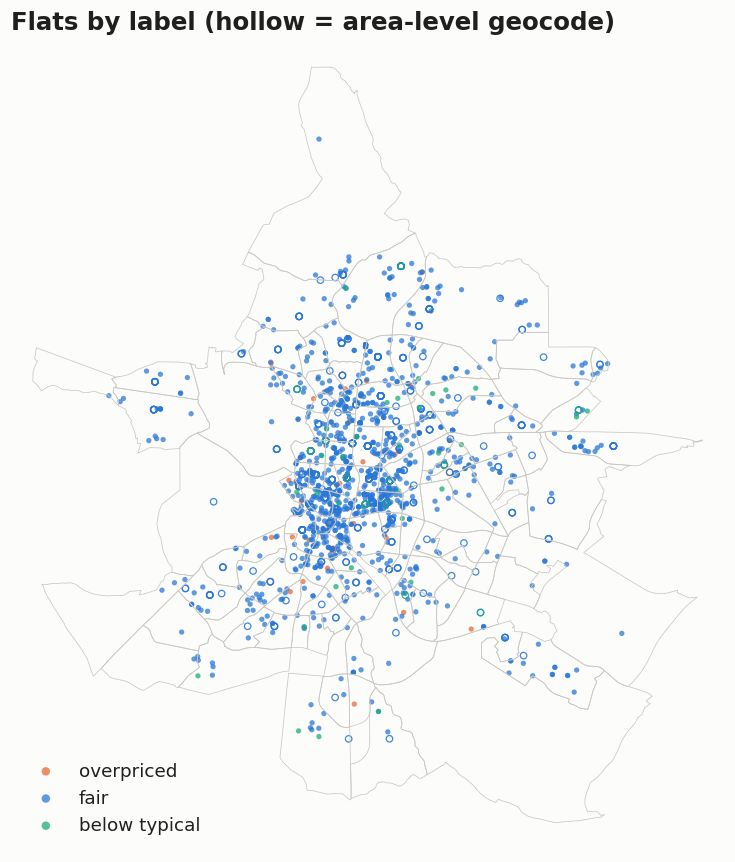

In [3]:
fig, ax = plt.subplots(figsize=(8.5, 8))
barrios_plot.boundary.plot(ax=ax, color="#c9c8c3", linewidth=0.5)
minx, miny, maxx, maxy = barrios_plot.total_bounds
ax.set_xlim(minx - 0.01, maxx + 0.01); ax.set_ylim(miny - 0.01, maxy + 0.01)
for lab in LABEL_ORDER:
    sub = pts[pts["label"] == lab]
    street = sub[sub["geocode_quality"] == "street-level"]
    area = sub[sub["geocode_quality"] == "area-level"]
    ax.scatter(street["lon"], street["lat"], s=12, color=LABEL_COL[lab], alpha=0.75, edgecolor="none",
               label=lab.replace("_", " "))
    ax.scatter(area["lon"], area["lat"], s=18, facecolor="none", edgecolor=LABEL_COL[lab], lw=0.8, alpha=0.9)
ax.set_title("Flats by label (hollow = area-level geocode)", loc="left")
ax.set_aspect(1.3)
ax.axis("off")
ax.legend(loc="lower left", markerscale=1.6)
plt.tight_layout(); plt.show()

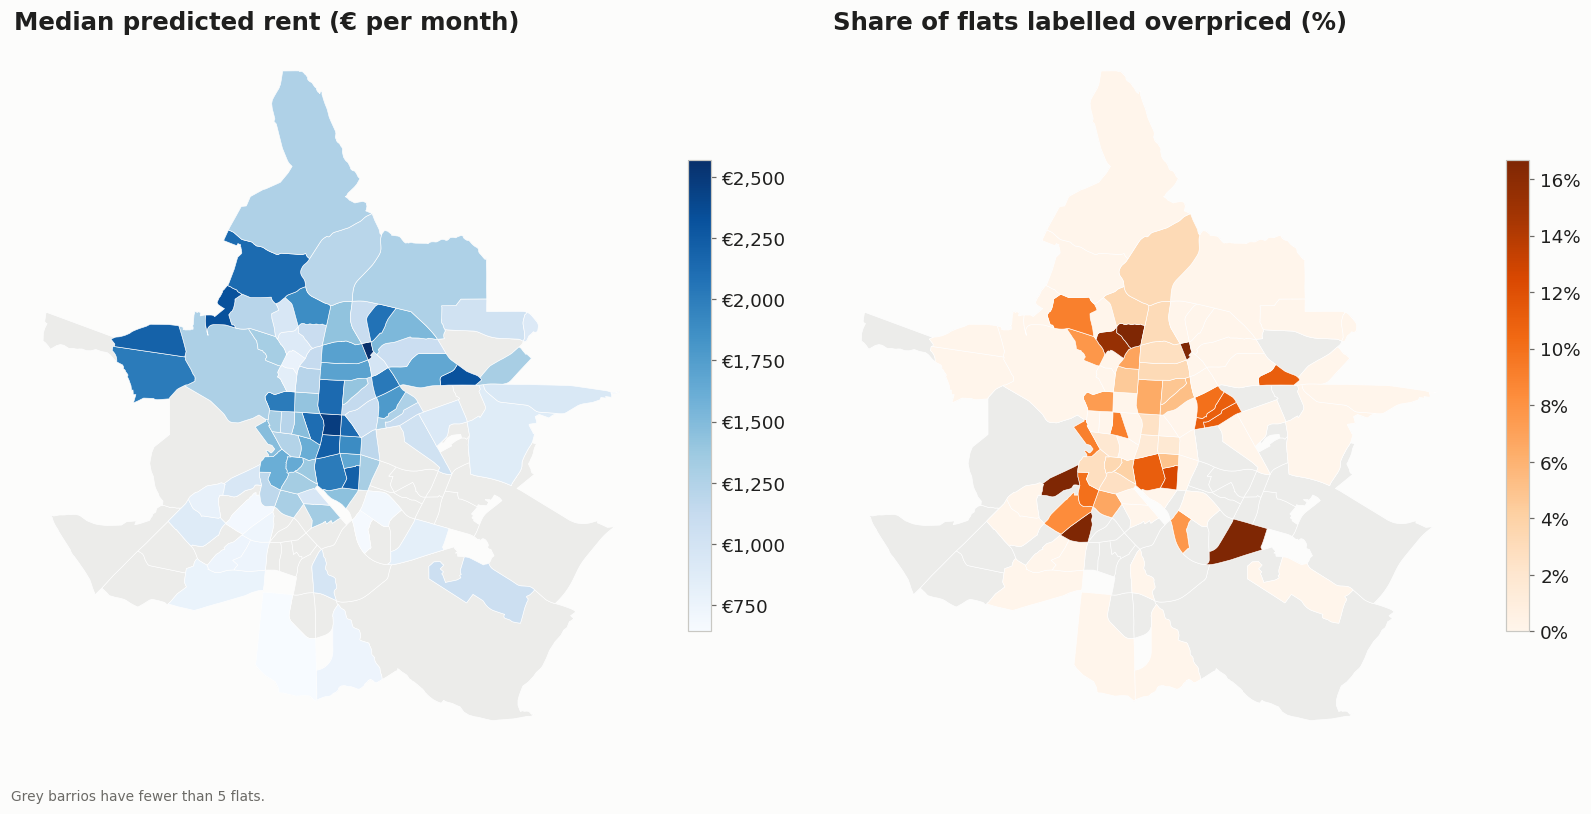

In [4]:
# Barrio choropleths: median predicted rent, and the share of flats labelled overpriced.
MIN_FLATS = 5
per = pts.dropna(subset=["NOMBRE"]).groupby("NOMBRE").agg(
    n=("Id", "size"), median_rent=("predicted", "median"),
    overpriced_share=("label", lambda s: (s == "overpriced").mean() * 100))
shape = barrios_plot.merge(per, left_on="NOMBRE", right_index=True, how="left")

fig, axes = plt.subplots(1, 2, figsize=(15, 7.5))
specs = [("median_rent", "Median predicted rent (€ per month)", "Blues", EUR),
         ("overpriced_share", "Share of flats labelled overpriced (%)", "Oranges", mtick.PercentFormatter(100, decimals=0))]
for ax, (col, title, cmap, fmt) in zip(axes, specs):
    shape.plot(ax=ax, color="#ececea", edgecolor="#ffffff", linewidth=0.4)
    ok = shape[shape["n"] >= MIN_FLATS]
    ok.plot(column=col, ax=ax, cmap=cmap, edgecolor="#ffffff", linewidth=0.4, legend=True,
            legend_kwds={"shrink": 0.6, "format": fmt} if col == "median_rent" else {"shrink": 0.6, "format": fmt})
    ax.set_title(title, loc="left"); ax.set_aspect(1.3); ax.axis("off")
fig.text(0.01, 0.01, f"Grey barrios have fewer than {MIN_FLATS} flats.", color=PAL["muted"], fontsize=9)
plt.tight_layout(); plt.show()

## 2. Where listings concentrate (density)

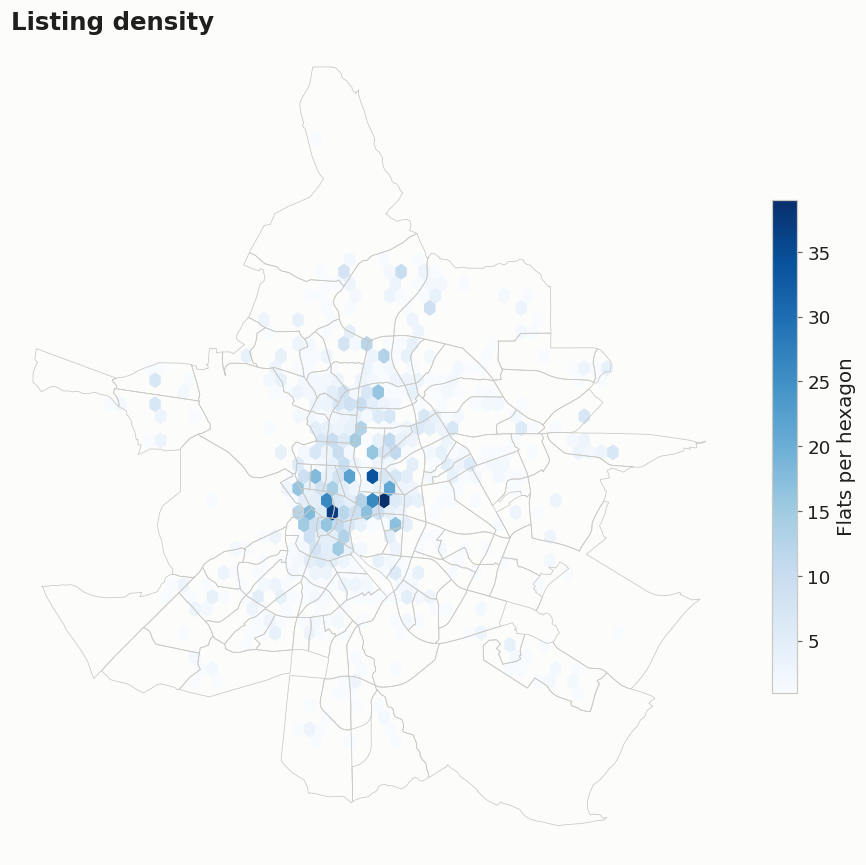

In [5]:
fig, ax = plt.subplots(figsize=(8.5, 8))
barrios_plot.boundary.plot(ax=ax, color="#c9c8c3", linewidth=0.5)
minx, miny, maxx, maxy = barrios_plot.total_bounds
ax.set_xlim(minx - 0.01, maxx + 0.01); ax.set_ylim(miny - 0.01, maxy + 0.01)
hb = ax.hexbin(mapped["lon"], mapped["lat"], gridsize=45, cmap="Blues", mincnt=1, linewidths=0)
cb = fig.colorbar(hb, ax=ax, shrink=0.6)
cb.set_label("Flats per hexagon")
ax.set_title("Listing density", loc="left")
ax.set_aspect(1.3); ax.axis("off")
plt.tight_layout(); plt.show()

## 3. A rent surface with decision boundaries

To draw a smooth surface, we need a model that sees coordinates. We first check with cross-validation whether coordinates improve the prediction, using the same features plus latitude and longitude.

In [6]:
# Compare the existing model with and without coordinates, on the same folds.
cv = KFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
y = df[TARGET].to_numpy(float)
ylog = np.log(y)
X_base, _ = prepare_xy(df)

coord_ok = df["lat"].notna().to_numpy()
X_geo = X_base.copy()
X_geo["lat"] = df["lat"].to_numpy()
X_geo["lon"] = df["lon"].to_numpy()

def gbm_pipe(num_cols):
    pre = ColumnTransformer([
        ("num", SimpleImputer(strategy="median", add_indicator=True), num_cols),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="unknown")),
                          ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10, sparse_output=False))]),
         CATEGORICAL_COLS)])
    return Pipeline([("pre", pre), ("m", HistGradientBoostingRegressor(learning_rate=0.05, max_iter=300, max_leaf_nodes=15,
                                                                      min_samples_leaf=10, l2_regularization=1.0, random_state=SEED))])

def mae(pred): return np.mean(np.abs(np.exp(pred) - y))

pred_base = cross_val_predict(gbm_pipe(NUMERIC_COLS), X_base, ylog, cv=cv)
pred_geo = cross_val_predict(gbm_pipe(NUMERIC_COLS + ["lat", "lon"]), X_geo, ylog, cv=cv)
print(f"Without coordinates: MAE €{mae(pred_base):,.0f}")
print(f"With coordinates:    MAE €{mae(pred_geo):,.0f}")

Without coordinates: MAE €260
With coordinates:    MAE €256


### Rent surface

We fit the coordinate model on all flats and predict rent for a reference flat (70 m², 2 bedrooms, with elevator, exterior-facing, floor 3, standard flat type) at every point on a grid across Madrid. Contour lines show where the predicted rent crosses €900, €1,200 and €1,500 per month. Those lines are the boundaries between price bands.

The surface is only trustworthy where there are flats, so it is masked outside the barrio polygons. It's also one reference flat, so it shows location effects only.

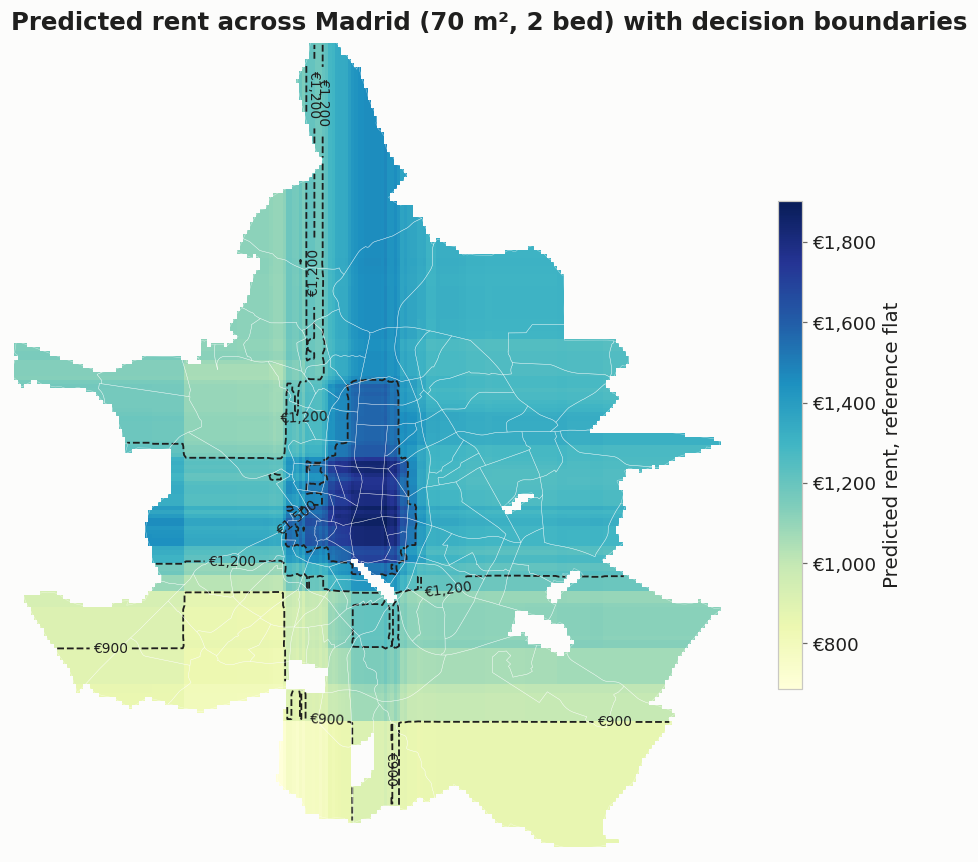

In [7]:
final = gbm_pipe(NUMERIC_COLS + ["lat", "lon"]).fit(X_geo[coord_ok], ylog[coord_ok])

REF = {"Bedrooms": 2, "Sq.Mt": 70, "Floor": 3, "Outer": 1, "Elevator": 1,
       "Penthouse": 0, "Cottage": 0, "Duplex": 0, "Semidetached": 0}
minx, miny, maxx, maxy = barrios_plot.total_bounds
lon_g = np.linspace(minx, maxx, 220)
lat_g = np.linspace(miny, maxy, 200)
LON, LAT = np.meshgrid(lon_g, lat_g)
grid = pd.DataFrame({**{k: v for k, v in REF.items()}}, index=range(LON.size))
grid["lat"] = LAT.ravel(); grid["lon"] = LON.ravel()
# Categorical fields: use the most common neighbourhood and district for the reference flat.
grid["Area"] = df["Area"].mode().iloc[0]
grid["District"] = df["District"].mode().iloc[0]
surf = np.exp(final.predict(grid[NUMERIC_COLS + ["lat", "lon"] + CATEGORICAL_COLS])).reshape(LON.shape)

plot_area = barrios_plot.dissolve().geometry.iloc[0]
inside = gpd.GeoSeries(gpd.points_from_xy(LON.ravel(), LAT.ravel()), crs=4326).within(plot_area).to_numpy().reshape(LON.shape)
surf_masked = np.where(inside, surf, np.nan)

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.pcolormesh(LON, LAT, surf_masked, cmap="YlGnBu", shading="auto")
cs = ax.contour(LON, LAT, surf_masked, levels=[900, 1200, 1500], colors=[PAL["ink"]], linewidths=1.2, linestyles="--")
ax.clabel(cs, fmt=lambda v: f"€{v:,.0f}", fontsize=9)
barrios_plot.boundary.plot(ax=ax, color="#ffffff", linewidth=0.3, alpha=0.6)
cb = fig.colorbar(im, ax=ax, shrink=0.6, format=EUR); cb.set_label("Predicted rent, reference flat")
ax.set_title("Predicted rent across Madrid (70 m², 2 bed) with decision boundaries", loc="left")
ax.set_aspect(1.3); ax.axis("off")
plt.tight_layout(); plt.show()

## Caveats

- **Geocoding is approximate.** Street-level results are usually close, but area-level results only place a flat somewhere in its neighbourhood.
- **Boundaries are model outputs, not market facts.** Contour lines show where the model predicts a rent threshold, given the reference flat. They are not observed price boundaries.
- **The surface is extrapolated where data is thin.** Outer areas with few flats are less reliable even inside the masked area.
- **Barrio names differ.** The listing neighbourhoods (`Area`) do not match the official barrios one-to-one, so the choropleths assign each flat by its coordinates instead.